# Decision Tree Models - PISA 2022

Decision Tree regression and classification using the shared cleaned PISA dataset, school-based folds, survey weights and all 10 plausible values.

In [26]:
import json
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    balanced_accuracy_score,
    recall_score
)

In [27]:
df = pd.read_parquet("../data/clean/pisa6_clean.parquet")

with open("../data/clean/columns.json") as f:
    roles = json.load(f)

folds = pd.read_csv("../data/clean/folds.csv")

print("Students:", len(df))
print("Columns:", len(df.columns))
print("Schools in folds file:", len(folds))

df.head()

Students: 61775
Columns: 158
Schools in folds file: 1973


,CNT,CNTSCHID,CNTSTUID,ESCS,PAREDINT,HISEI,HOMEPOS,ANXMAT,MATHEFF,MATHEF21,...,BELONG_missing,BULLIED_missing,EDUSHORT_missing,STAFFSHORT_missing,MCLSIZE_missing,STRATIO_missing,SCHL_PRIVATE_missing,SCHSIZE_log_missing,DISTRACTED_OWN,DISTRACTED_OTHERS
0,PSE,27500099,27500001,-0.6594,16.0,NaN,-0.5451,NaN,-1.7181,NaN,...,0,0,0,0,0,0,0,0,NaN,NaN
1,PSE,27500050,27500002,-0.7512,12.0,75.43,-1.8665,0.4067,-1.2825,-0.5623,...,0,0,0,0,0,0,0,0,NaN,1.0
2,PSE,27500157,27500003,-0.7349,16.0,16.50,-0.7994,0.9050,-0.3051,-0.2354,...,0,0,0,0,0,0,0,0,0.0,0.0
3,PSE,27500213,27500004,1.6743,16.0,76.65,2.2074,NaN,0.0501,NaN,...,0,0,0,0,0,0,0,0,NaN,NaN
4,PSE,27500038,27500005,-1.7778,12.0,23.57,-1.9787,0.4290,0.1033,-2.0992,...,0,0,0,0,0,0,0,0,NaN,0.0


In [28]:
print(roles.keys())

dict_keys(['ids', 'targets', 'feature_groups', 'missing_indicators', 'flags', 'weights', 'side_questions', 'quality_flags', 'eda_only', 'audit_only'])


In [29]:
roles["feature_groups"]

{'family': ['ESCS', 'PAREDINT', 'HISEI', 'HOMEPOS'],
 'maths_attitudes': ['ANXMAT', 'MATHEFF', 'MATHEF21'],
 'classroom': ['DISCLIM', 'TEACHSUP'],
 'climate_resources': ['BELONG', 'BULLIED', 'EDUSHORT', 'STAFFSHORT'],
 'school_org': ['MCLSIZE', 'STRATIO', 'SCHL_PRIVATE', 'SCHSIZE_log']}

In [30]:
features = [
    c
    for cols in roles["feature_groups"].values()
    for c in cols
]

print("Number of features:", len(features))
print(features)

Number of features: 17
['ESCS', 'PAREDINT', 'HISEI', 'HOMEPOS', 'ANXMAT', 'MATHEFF', 'MATHEF21', 'DISCLIM', 'TEACHSUP', 'BELONG', 'BULLIED', 'EDUSHORT', 'STAFFSHORT', 'MCLSIZE', 'STRATIO', 'SCHL_PRIVATE', 'SCHSIZE_log']


In [31]:
X = df[features]

In [32]:
print("Targets:")
print(roles["targets"])

print("\nWeights:")
print(roles["weights"])

print("\nMissing indicators:")
print(roles["missing_indicators"])

Targets:
{'regression': ['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH'], 'classification': ['BELOW_L2_PV1', 'BELOW_L2_PV2', 'BELOW_L2_PV3', 'BELOW_L2_PV4', 'BELOW_L2_PV5', 'BELOW_L2_PV6', 'BELOW_L2_PV7', 'BELOW_L2_PV8', 'BELOW_L2_PV9', 'BELOW_L2_PV10'], 'level2_cutoff': 420.07}

Weights:
{'final': 'W_FSTUWT', 'senate': 'SENWT', 'replicates': ['W_FSTURWT1', 'W_FSTURWT2', 'W_FSTURWT3', 'W_FSTURWT4', 'W_FSTURWT5', 'W_FSTURWT6', 'W_FSTURWT7', 'W_FSTURWT8', 'W_FSTURWT9', 'W_FSTURWT10', 'W_FSTURWT11', 'W_FSTURWT12', 'W_FSTURWT13', 'W_FSTURWT14', 'W_FSTURWT15', 'W_FSTURWT16', 'W_FSTURWT17', 'W_FSTURWT18', 'W_FSTURWT19', 'W_FSTURWT20', 'W_FSTURWT21', 'W_FSTURWT22', 'W_FSTURWT23', 'W_FSTURWT24', 'W_FSTURWT25', 'W_FSTURWT26', 'W_FSTURWT27', 'W_FSTURWT28', 'W_FSTURWT29', 'W_FSTURWT30', 'W_FSTURWT31', 'W_FSTURWT32', 'W_FSTURWT33', 'W_FSTURWT34', 'W_FSTURWT35', 'W_FSTURWT36', 'W_FSTURWT37', 'W_FSTURWT38', 'W_FSTURWT39', 'W_FSTURWT40', 

In [33]:
folds.head()

,CNTSCHID,CNT,fold,n_students
0,27500001,PSE,2,10
1,27500002,PSE,4,35
2,27500003,PSE,0,35
3,27500004,PSE,3,15
4,27500005,PSE,1,33


In [34]:
folds["fold"].value_counts().sort_index()

fold
0    397
1    396
2    394
3    394
4    392
Name: count, dtype: int64

In [35]:
df = df.merge(
    folds[["CNT", "CNTSCHID", "fold"]],
    on=["CNT", "CNTSCHID"],
    how="left"
)

print(df["fold"].value_counts().sort_index())
print("Missing fold assignments:", df["fold"].isna().sum())

fold
0    12340
1    12330
2    12365
3    12361
4    12379
Name: count, dtype: int64
Missing fold assignments: 0


In [36]:
train = df[df["fold"] != 0].copy()
test = df[df["fold"] == 0].copy()

print("Training students:", len(train))
print("Test students:", len(test))

Training students: 49435
Test students: 12340


In [37]:
#first practice train
X_train = train[features]
y_train = train["PV1MATH"]

X_test = test[features]
y_test = test["PV1MATH"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (49435, 17)
y_train shape: (49435,)


In [38]:
print("Missing values in training features:")
print(X_train.isna().sum())

print("\nTotal missing values in X_train:")
print(X_train.isna().sum().sum())

print("\nTotal missing values in X_test:")
print(X_test.isna().sum().sum())

Missing values in training features:
ESCS             1854
PAREDINT         2026
HISEI            7052
HOMEPOS          1324
ANXMAT          11117
MATHEFF         10247
MATHEF21        10882
DISCLIM          8210
TEACHSUP         8727
BELONG           4471
BULLIED          4359
EDUSHORT         4035
STAFFSHORT       4066
MCLSIZE          4022
STRATIO          7869
SCHL_PRIVATE     2042
SCHSIZE_log      6087
dtype: int64

Total missing values in X_train:
98390

Total missing values in X_test:
25877


In [39]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (12340, 17)
y_test shape: (12340,)


In [40]:
from sklearn.impute import SimpleImputer

In [41]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

print("Missing after imputation in train:", np.isnan(X_train_imputed).sum())
print("Missing after imputation in test:", np.isnan(X_test_imputed).sum())

Missing after imputation in train: 0
Missing after imputation in test: 0


In [42]:
missing_flags = [
    c
    for cols in roles["missing_indicators"].values()
    for c in cols
]

model_features = features + missing_flags

print("Main predictors:", len(features))
print("Missing flags:", len(missing_flags))
print("Total model inputs:", len(model_features))

Main predictors: 17
Missing flags: 17
Total model inputs: 34


In [43]:
X_train = train[model_features]
X_test = test[model_features]

y_train = train["PV1MATH"]
y_test = test["PV1MATH"]

w_train = train["SENWT"]
w_test = test["SENWT"]

In [44]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Train missing:", np.isnan(X_train_imputed).sum())
print("Test missing:", np.isnan(X_test_imputed).sum())

Train missing: 0
Test missing: 0


In [45]:
model = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=100,
    random_state=42
)

model.fit(
    X_train_imputed,
    y_train,
    sample_weight=w_train
)

print("Decision Tree trained successfully")

Decision Tree trained successfully


In [46]:
predictions = model.predict(X_test_imputed)

print("Number of predictions:", len(predictions))
print("First 10 predictions:")
print(predictions[:10])

Number of predictions: 12340
First 10 predictions:
[343.25679073 412.38953645 433.7423748  354.2239045  380.81888171
 354.2239045  412.38953645 354.2239045  354.2239045  383.16405714]


In [47]:
rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions,
        sample_weight=w_test
    )
)

mae = mean_absolute_error(
    y_test,
    predictions,
    sample_weight=w_test
)

r2 = r2_score(
    y_test,
    predictions,
    sample_weight=w_test
)

print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R²:", round(r2, 3))

RMSE: 67.23
MAE: 53.07
R²: 0.334


In [48]:
# trying diff depths of decision trees to see if we can improve the model performance

from sklearn.impute import SimpleImputer

depths = [3, 4, 5, 6, 8, 10]
leaf_sizes = [50, 100, 200]

tuning_results = []

for depth in depths:
    for leaf_size in leaf_sizes:

        fold_rmses = []

        for test_fold in range(5):

            train_fold = df[df["fold"] != test_fold].copy()
            test_fold_df = df[df["fold"] == test_fold].copy()

            X_train = train_fold[model_features]
            X_test = test_fold_df[model_features]

            y_train = train_fold["PV1MATH"]
            y_test = test_fold_df["PV1MATH"]

            w_train = train_fold["SENWT"]
            w_test = test_fold_df["SENWT"]

            # Learn medians ONLY from training data
            imputer = SimpleImputer(strategy="median")

            X_train_imp = imputer.fit_transform(X_train)
            X_test_imp = imputer.transform(X_test)

            # Train tree
            model = DecisionTreeRegressor(
                max_depth=depth,
                min_samples_leaf=leaf_size,
                random_state=42
            )

            model.fit(
                X_train_imp,
                y_train,
                sample_weight=w_train
            )

            predictions = model.predict(X_test_imp)

            rmse = np.sqrt(
                mean_squared_error(
                    y_test,
                    predictions,
                    sample_weight=w_test
                )
            )

            fold_rmses.append(rmse)

        tuning_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "mean_RMSE": np.mean(fold_rmses)
        })

tuning_results = pd.DataFrame(tuning_results)

tuning_results.sort_values("mean_RMSE").round(2)

,max_depth,min_samples_leaf,mean_RMSE
17,10,200,64.20
14,8,200,64.26
13,8,100,64.30
16,10,100,64.37
12,8,50,64.43
10,6,100,64.57
11,6,200,64.62
9,6,50,64.66
15,10,50,64.75
7,5,100,65.38


In [49]:
# regression evaluation across all targets and folds

final_results = []

regression_targets = roles["targets"]["regression"]

for target in regression_targets:

    for test_fold in range(5):

        # Split by school fold
        train_fold = df[df["fold"] != test_fold].copy()
        test_fold_df = df[df["fold"] == test_fold].copy()

        # Inputs and target
        X_train = train_fold[model_features]
        X_test = test_fold_df[model_features]

        y_train = train_fold[target]
        y_test = test_fold_df[target]

        # Survey/system weights
        w_train = train_fold["SENWT"]
        w_test = test_fold_df["SENWT"]

        # Imputation learned only from training data
        imputer = SimpleImputer(strategy="median")

        X_train_imp = imputer.fit_transform(X_train)
        X_test_imp = imputer.transform(X_test)

        # Final tuned tree
        model = DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=200,
            random_state=42
        )

        model.fit(
            X_train_imp,
            y_train,
            sample_weight=w_train
        )

        predictions = model.predict(X_test_imp)

        # Metrics
        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                predictions,
                sample_weight=w_test
            )
        )

        mae = mean_absolute_error(
            y_test,
            predictions,
            sample_weight=w_test
        )

        r2 = r2_score(
            y_test,
            predictions,
            sample_weight=w_test
        )

        final_results.append({
            "target": target,
            "fold": test_fold,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

final_results = pd.DataFrame(final_results)

final_results.head()

,target,fold,RMSE,MAE,R2
0,PV1MATH,0,65.262159,51.158889,0.372824
1,PV1MATH,1,64.074756,50.109581,0.361395
2,PV1MATH,2,63.706878,49.842259,0.332277
3,PV1MATH,3,64.417555,50.632389,0.389111
4,PV1MATH,4,63.550374,49.644616,0.371604


In [50]:
print("Number of runs:", len(final_results))

print("\nOverall Decision Tree regression performance:")

print(
    final_results[["RMSE", "MAE", "R2"]]
    .mean()
    .round(3)
)

Number of runs: 50

Overall Decision Tree regression performance:
RMSE    64.115
MAE     50.212
R2       0.364
dtype: float64


In [51]:
# Gives avg performance across folds and targets, as well as std, min, max for each metric
performance_summary = (
    final_results[["RMSE", "MAE", "R2"]]
    .agg(["mean", "std", "min", "max"])
    .T
    .round(3)
)

performance_summary

,mean,std,min,max
RMSE,64.115,0.509,63.152,65.539
MAE,50.212,0.466,49.433,51.405
R2,0.364,0.024,0.307,0.395


In [52]:
# Did PV1, PV2, ... PV10 give roughly similar results?

performance_by_pv = (
    final_results
    .groupby("target")[["RMSE", "MAE", "R2"]]
    .mean()
    .round(3)
)

performance_by_pv

,RMSE,MAE,R2
target,,,
PV10MATH,63.703,49.892,0.363
PV1MATH,64.202,50.278,0.365
PV2MATH,64.330,50.399,0.360
PV3MATH,64.210,50.220,0.364
PV4MATH,64.087,50.147,0.362
PV5MATH,64.058,50.136,0.368
PV6MATH,63.946,50.094,0.366
PV7MATH,64.199,50.296,0.363
PV8MATH,64.013,50.137,0.363


In [53]:
# Does the model work reasonably consistently across the five different groups of schools?

performance_by_fold = (
    final_results
    .groupby("fold")[["RMSE", "MAE", "R2"]]
    .mean()
    .round(3)
)

performance_by_fold

,RMSE,MAE,R2
fold,,,
0,64.637,50.614,0.380
1,63.540,49.804,0.366
2,64.079,50.085,0.322
3,64.347,50.633,0.388
4,63.974,49.924,0.363


In [54]:
# comparing with a simple baseline model

baseline_results = []

for target in regression_targets:

    for test_fold in range(5):

        train_fold = df[df["fold"] != test_fold].copy()
        test_fold_df = df[df["fold"] == test_fold].copy()

        y_train = train_fold[target]
        y_test = test_fold_df[target]

        w_train = train_fold["SENWT"]
        w_test = test_fold_df["SENWT"]

        # Weighted average maths score learned from training data only
        weighted_mean = np.average(
            y_train,
            weights=w_train
        )

        # Predict that same average for every test student
        baseline_predictions = np.full(
            len(test_fold_df),
            weighted_mean
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                baseline_predictions,
                sample_weight=w_test
            )
        )

        mae = mean_absolute_error(
            y_test,
            baseline_predictions,
            sample_weight=w_test
        )

        r2 = r2_score(
            y_test,
            baseline_predictions,
            sample_weight=w_test
        )

        baseline_results.append({
            "target": target,
            "fold": test_fold,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

baseline_results = pd.DataFrame(baseline_results)

In [55]:
baseline_summary = (
    baseline_results[["RMSE", "MAE", "R2"]]
    .mean()
    .round(3)
)

baseline_summary

RMSE    80.438
MAE     62.759
R2      -0.001
dtype: float64

In [56]:
comparison = pd.DataFrame({
    "Decision Tree": final_results[["RMSE", "MAE", "R2"]].mean(),
    "Mean Baseline": baseline_results[["RMSE", "MAE", "R2"]].mean()
}).round(3)

comparison

,Decision Tree,Mean Baseline
RMSE,64.115,80.438
MAE,50.212,62.759
R2,0.364,-0.001


In [57]:
rmse_improvement = (
    (
        baseline_results["RMSE"].mean()
        - final_results["RMSE"].mean()
    )
    / baseline_results["RMSE"].mean()
    * 100
)

print(
    "RMSE improvement over mean baseline:",
    round(rmse_improvement, 1),
    "%"
)

RMSE improvement over mean baseline: 20.3 %


In [58]:
# feature importance across all 50 models

importance_results = []

for target in regression_targets:

    for test_fold in range(5):

        train_fold = df[df["fold"] != test_fold].copy()
        test_fold_df = df[df["fold"] == test_fold].copy()

        X_train = train_fold[model_features]
        X_test = test_fold_df[model_features]

        y_train = train_fold[target]
        w_train = train_fold["SENWT"]

        # Imputation using training data only
        imputer = SimpleImputer(strategy="median")

        X_train_imp = imputer.fit_transform(X_train)
        X_test_imp = imputer.transform(X_test)

        # Same final tuned Decision Tree
        model = DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=200,
            random_state=42
        )

        model.fit(
            X_train_imp,
            y_train,
            sample_weight=w_train
        )

        # Save feature importance from this tree
        for feature, importance in zip(
            model_features,
            model.feature_importances_
        ):
            importance_results.append({
                "target": target,
                "fold": test_fold,
                "feature": feature,
                "importance": importance
            })

importance_results = pd.DataFrame(importance_results)

print("Rows collected:", len(importance_results))

Rows collected: 1700


In [59]:
mean_importance = (
    importance_results
    .groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(4)
)

mean_importance.head(15)

,mean,std
feature,,
SCHL_PRIVATE,0.3808,0.0110
MATHEFF,0.2527,0.0054
ESCS,0.0852,0.0205
HISEI,0.0469,0.0125
SCHSIZE_log,0.0420,0.0068
BULLIED,0.0397,0.0049
HOMEPOS,0.0318,0.0051
SCHL_PRIVATE_missing,0.0307,0.0075
ANXMAT,0.0178,0.0025


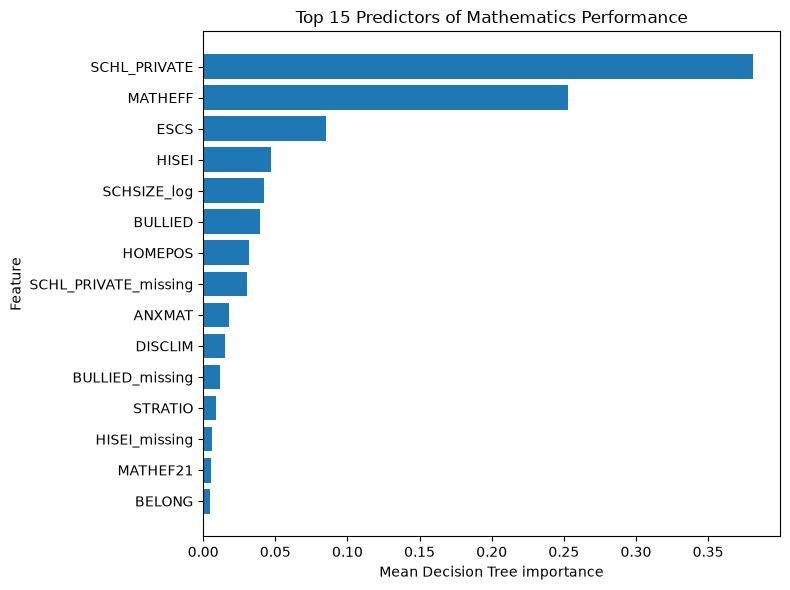

In [60]:
# plotting the graph

import matplotlib.pyplot as plt

top15 = mean_importance.head(15).sort_values("mean")

plt.figure(figsize=(8, 6))

plt.barh(
    top15.index,
    top15["mean"]
)

plt.xlabel("Mean Decision Tree importance")
plt.ylabel("Feature")
plt.title("Top 15 Predictors of Mathematics Performance")

plt.tight_layout()
plt.show()

In [61]:
# Map every feature to its factor group (family, maths_attitudes, classroom, climate_resources, school_org)

feature_to_group = {}

for group, cols in roles["feature_groups"].items():
    for col in cols:
        feature_to_group[col] = group

# Also assign missing indicators to the same factor groups
for group, cols in roles["missing_indicators"].items():
    for col in cols:
        feature_to_group[col] = group

# Add group name to every importance result
importance_results["group"] = importance_results["feature"].map(feature_to_group)

print("Unmapped features:", importance_results["group"].isna().sum())

Unmapped features: 0


In [62]:
# finding importance of whole factor groups, rather than individual features

group_importance_runs = (
    importance_results
    .groupby(["target", "fold", "group"], as_index=False)["importance"]
    .sum()
)

group_importance = (
    group_importance_runs
    .groupby("group")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(4)
)

group_importance

,mean,std
group,,
school_org,0.4643,0.0163
maths_attitudes,0.2772,0.0050
family,0.1771,0.0154
climate_resources,0.0634,0.0050
classroom,0.0180,0.0038


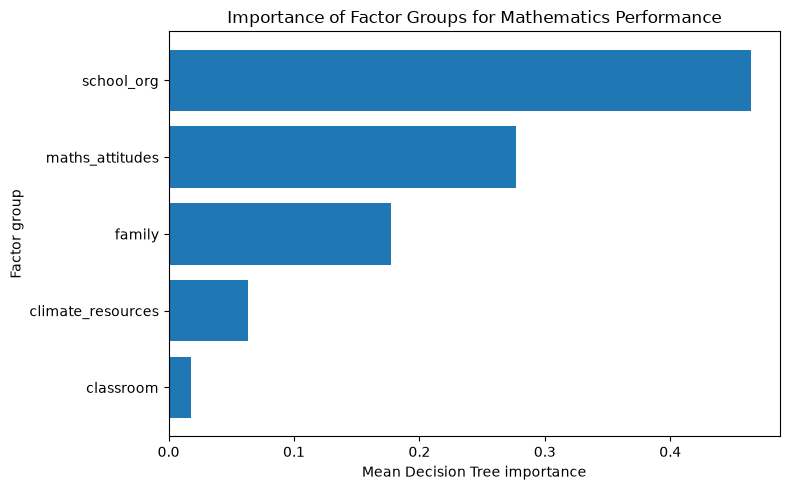

In [63]:
# graph-ing it

group_plot = group_importance.sort_values("mean")

plt.figure(figsize=(8, 5))

plt.barh(
    group_plot.index,
    group_plot["mean"]
)

plt.xlabel("Mean Decision Tree importance")
plt.ylabel("Factor group")
plt.title("Importance of Factor Groups for Mathematics Performance")

plt.tight_layout()
plt.show()

In [64]:
# held-out test set permutation importance

permutation_results = []

for pv_index, target in enumerate(regression_targets):

    for test_fold in range(5):

        train_fold = df[df["fold"] != test_fold].copy()
        test_fold_df = df[df["fold"] == test_fold].copy()

        X_train = train_fold[model_features]
        X_test = test_fold_df[model_features]

        y_train = train_fold[target]
        y_test = test_fold_df[target]

        w_train = train_fold["SENWT"]
        w_test = test_fold_df["SENWT"]

        # Imputation learned from training data only
        imputer = SimpleImputer(strategy="median")
        X_train_imp = imputer.fit_transform(X_train)
        X_test_imp = imputer.transform(X_test)

        # Final tuned tree
        model = DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=200,
            random_state=42
        )

        model.fit(
            X_train_imp,
            y_train,
            sample_weight=w_train
        )

        # Normal performance on untouched test data
        base_predictions = model.predict(X_test_imp)

        base_rmse = np.sqrt(
            mean_squared_error(
                y_test,
                base_predictions,
                sample_weight=w_test
            )
        )

        # Only test the 17 substantive predictors here
        for feature in features:

            feature_index = model_features.index(feature)

            for repeat in range(3):

                X_permuted = X_test_imp.copy()

                rng = np.random.default_rng(
                    42
                    + pv_index * 1000
                    + test_fold * 100
                    + feature_index * 10
                    + repeat
                )

                X_permuted[:, feature_index] = rng.permutation(
                    X_permuted[:, feature_index]
                )

                perm_predictions = model.predict(X_permuted)

                perm_rmse = np.sqrt(
                    mean_squared_error(
                        y_test,
                        perm_predictions,
                        sample_weight=w_test
                    )
                )

                permutation_results.append({
                    "target": target,
                    "fold": test_fold,
                    "feature": feature,
                    "repeat": repeat,
                    "delta_RMSE": perm_rmse - base_rmse
                })

permutation_results = pd.DataFrame(permutation_results)

print("Rows:", len(permutation_results))

Rows: 2550


In [65]:
permutation_summary = (
    permutation_results
    .groupby("feature")["delta_RMSE"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(3)
)

permutation_summary

,mean,std
feature,,
SCHL_PRIVATE,6.289,0.812
MATHEFF,5.991,0.402
ESCS,2.924,0.664
BULLIED,1.557,0.266
SCHSIZE_log,1.305,0.382
HISEI,1.237,0.334
HOMEPOS,0.946,0.285
ANXMAT,0.656,0.198
DISCLIM,0.435,0.157


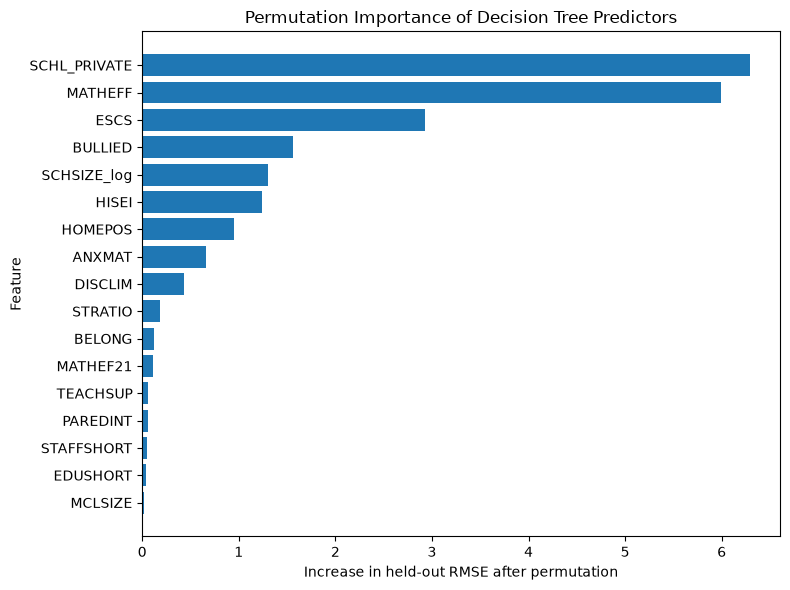

In [66]:
# plot

perm_plot = permutation_summary.sort_values("mean")

plt.figure(figsize=(8, 6))

plt.barh(
    perm_plot.index,
    perm_plot["mean"]
)

plt.xlabel("Increase in held-out RMSE after permutation")
plt.ylabel("Feature")
plt.title("Permutation Importance of Decision Tree Predictors")

plt.tight_layout()
plt.show()

In [67]:
# within country permutation importance

within_country_perm_results = []

for pv_index, target in enumerate(regression_targets):

    for test_fold in range(5):

        train_fold = df[df["fold"] != test_fold].copy()
        test_fold_df = df[df["fold"] == test_fold].copy()

        X_train = train_fold[model_features]
        X_test = test_fold_df[model_features]

        y_train = train_fold[target]
        y_test = test_fold_df[target]

        w_train = train_fold["SENWT"]
        w_test = test_fold_df["SENWT"]

        # Imputation using training data only
        imputer = SimpleImputer(strategy="median")

        X_train_imp = imputer.fit_transform(X_train)
        X_test_imp = imputer.transform(X_test)

        # Final tuned tree
        model = DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=200,
            random_state=42
        )

        model.fit(
            X_train_imp,
            y_train,
            sample_weight=w_train
        )

        # Normal held-out performance
        base_predictions = model.predict(X_test_imp)

        base_rmse = np.sqrt(
            mean_squared_error(
                y_test,
                base_predictions,
                sample_weight=w_test
            )
        )

        # DataFrame makes within-country shuffling easier
        X_test_imp_df = pd.DataFrame(
            X_test_imp,
            columns=model_features,
            index=test_fold_df.index
        )

        for feature in features:

            for repeat in range(3):

                X_permuted = X_test_imp_df.copy()

                rng = np.random.default_rng(
                    100
                    + pv_index * 1000
                    + test_fold * 100
                    + model_features.index(feature) * 10
                    + repeat
                )

                # Shuffle ONLY within each education system
                for country, indices in test_fold_df.groupby("CNT").groups.items():

                    values = X_permuted.loc[indices, feature].to_numpy().copy()

                    X_permuted.loc[indices, feature] = rng.permutation(values)

                perm_predictions = model.predict(
                    X_permuted[model_features].to_numpy()
                )

                perm_rmse = np.sqrt(
                    mean_squared_error(
                        y_test,
                        perm_predictions,
                        sample_weight=w_test
                    )
                )

                within_country_perm_results.append({
                    "target": target,
                    "fold": test_fold,
                    "feature": feature,
                    "repeat": repeat,
                    "delta_RMSE": perm_rmse - base_rmse
                })

within_country_perm_results = pd.DataFrame(
    within_country_perm_results
)

print("Rows:", len(within_country_perm_results))

Rows: 2550


In [68]:
within_country_perm_summary = (
    within_country_perm_results
    .groupby("feature")["delta_RMSE"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(3)
)

within_country_perm_summary

,mean,std
feature,,
MATHEFF,5.658,0.413
SCHL_PRIVATE,4.652,0.596
ESCS,1.966,0.509
BULLIED,1.496,0.246
HISEI,0.994,0.256
SCHSIZE_log,0.945,0.424
HOMEPOS,0.771,0.207
ANXMAT,0.649,0.195
DISCLIM,0.397,0.142


In [69]:
# compare the 2 permutation importance results

permutation_comparison = pd.DataFrame({
    "Global permutation": permutation_summary["mean"],
    "Within-country permutation": within_country_perm_summary["mean"]
})

permutation_comparison = (
    permutation_comparison
    .sort_values(
        "Global permutation",
        ascending=False
    )
    .round(3)
)

permutation_comparison

,Global permutation,Within-country permutation
feature,,
SCHL_PRIVATE,6.289,4.652
MATHEFF,5.991,5.658
ESCS,2.924,1.966
BULLIED,1.557,1.496
SCHSIZE_log,1.305,0.945
HISEI,1.237,0.994
HOMEPOS,0.946,0.771
ANXMAT,0.656,0.649
DISCLIM,0.435,0.397


In [70]:
# All students are now used because evaluation is already finished

X_full = df[model_features]
y_full = df["PV1MATH"]
w_full = df["SENWT"]

final_imputer = SimpleImputer(strategy="median")
X_full_imp = final_imputer.fit_transform(X_full)

final_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=200,
    random_state=42
)

final_tree.fit(
    X_full_imp,
    y_full,
    sample_weight=w_full
)

print("Final interpretation tree trained.")

Final interpretation tree trained.


In [71]:
from sklearn.tree import export_text

In [72]:
rules = export_text(
    final_tree,
    feature_names=model_features,
    max_depth=3,
    decimals=2
)

print(rules)

|--- SCHL_PRIVATE <= 0.50
|   |--- MATHEFF <= -0.43
|   |   |--- HISEI <= 65.07
|   |   |   |--- BULLIED <= 1.32
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- BULLIED >  1.32
|   |   |   |   |--- truncated branch of depth 6
|   |   |--- HISEI >  65.07
|   |   |   |--- SCHL_PRIVATE_missing <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- SCHL_PRIVATE_missing >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- MATHEFF >  -0.43
|   |   |--- ESCS <= 0.03
|   |   |   |--- BULLIED <= 1.44
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- BULLIED >  1.44
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- ESCS >  0.03
|   |   |   |--- SCHL_PRIVATE_missing <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- SCHL_PRIVATE_missing >  0.50
|   |   |   |   |--- truncated branch of depth 3
|--- SCHL_PRIVATE >  0.50
|   |--- MATHEFF <= 0.03
|   |   |--- ESCS <= -0.02
|   |   |   |--- HOMEPOS <= 

In [73]:
# better readable rules

tree = final_tree.tree_

leaf_rules = []

def collect_rules(node=0, conditions=None):
    if conditions is None:
        conditions = []

    left = tree.children_left[node]
    right = tree.children_right[node]

    # If this is a leaf
    if left == right:
        leaf_rules.append({
            "rule": " AND ".join(conditions),
            "predicted_math": float(tree.value[node].squeeze()),
            "weighted_students": tree.weighted_n_node_samples[node],
            "depth": len(conditions)
        })
        return

    feature = model_features[tree.feature[node]]
    threshold = tree.threshold[node]

    collect_rules(
        left,
        conditions + [f"{feature} <= {threshold:.2f}"]
    )

    collect_rules(
        right,
        conditions + [f"{feature} > {threshold:.2f}"]
    )

collect_rules()

leaf_rules_df = pd.DataFrame(leaf_rules)

leaf_rules_df["weight_share"] = (
    leaf_rules_df["weighted_students"]
    / tree.weighted_n_node_samples[0]
)

top_rules = (
    leaf_rules_df
    .sort_values("weight_share", ascending=False)
    .head(10)
)

top_rules[
    ["rule", "predicted_math", "weight_share", "depth"]
].round({
    "predicted_math": 1,
    "weight_share": 3
})

,rule,predicted_math,weight_share,depth
2,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,343.8,0.040,10
1,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,337.2,0.027,10
59,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,381.1,0.025,10
14,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,364.9,0.022,10
19,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,378.6,0.021,10
3,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,357.4,0.016,10
25,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,384.2,0.014,10
8,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,371.4,0.012,10
15,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND ...,350.2,0.011,10
149,SCHL_PRIVATE > 0.50 AND MATHEFF <= 0.03 AND ES...,427.1,0.010,10


In [74]:
pd.set_option("display.max_colwidth", None)

top_rules[
    ["rule", "predicted_math", "weight_share", "depth"]
].round({
    "predicted_math": 1,
    "weight_share": 3
})

,rule,predicted_math,weight_share,depth
2,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS <= -1.52 AND BELONG <= -0.07 AND SCHSIZE_log <= 7.19 AND HOMEPOS > -2.50 AND DISCLIM <= -0.08,343.8,0.040,10
1,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS <= -1.52 AND BELONG <= -0.07 AND SCHSIZE_log <= 7.19 AND HOMEPOS <= -2.50 AND MATHEFF > -2.14,337.2,0.027,10
59,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI > 65.07 AND SCHL_PRIVATE_missing <= 0.50 AND ESCS > -0.06 AND DISCLIM <= -0.08 AND BULLIED <= 1.30 AND DISCLIM > -1.32 AND BULLIED_missing <= 0.50 AND STRATIO > 10.51,381.1,0.025,10
14,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS > -1.52 AND DISCLIM <= -0.08 AND BELONG <= -0.33 AND DISCLIM > -1.04 AND TEACHSUP_missing <= 0.50,364.9,0.022,10
19,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS > -1.52 AND DISCLIM <= -0.08 AND BELONG > -0.33 AND MATHEFF > -1.31 AND ESCS > -1.29,378.6,0.021,10
3,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS <= -1.52 AND BELONG <= -0.07 AND SCHSIZE_log <= 7.19 AND HOMEPOS > -2.50 AND DISCLIM > -0.08,357.4,0.016,10
25,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS > -1.52 AND DISCLIM > -0.08 AND MATHEFF > -1.29 AND STRATIO <= 15.91 AND ANXMAT > -0.05,384.2,0.014,10
8,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS <= -1.52 AND BELONG > -0.07 AND MCLSIZE <= 40.50 AND MATHEFF > -1.05 AND TEACHSUP_missing <= 0.50,371.4,0.012,10
15,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS > -1.52 AND DISCLIM <= -0.08 AND BELONG <= -0.33 AND DISCLIM > -1.04 AND TEACHSUP_missing > 0.50,350.2,0.011,10
149,SCHL_PRIVATE > 0.50 AND MATHEFF <= 0.03 AND ESCS > -0.02 AND MATHEFF <= -0.43 AND HISEI_missing <= 0.50 AND SCHSIZE_log > 6.83 AND DISCLIM <= -0.08 AND STRATIO_missing <= 0.50 AND ANXMAT > -0.04 AND HISEI > 73.81,427.1,0.010,10


In [75]:
for i, row in top_rules.iterrows():
    print("\nRULE", i)
    print(row["rule"])
    print("Predicted maths:", round(row["predicted_math"], 1))
    print("Weight share:", round(row["weight_share"] * 100, 1), "%")


RULE 2
SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS <= -1.52 AND BELONG <= -0.07 AND SCHSIZE_log <= 7.19 AND HOMEPOS > -2.50 AND DISCLIM <= -0.08
Predicted maths: 343.8
Weight share: 4.0 %

RULE 1
SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS <= -1.52 AND BELONG <= -0.07 AND SCHSIZE_log <= 7.19 AND HOMEPOS <= -2.50 AND MATHEFF > -2.14
Predicted maths: 337.2
Weight share: 2.7 %

RULE 59
SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI > 65.07 AND SCHL_PRIVATE_missing <= 0.50 AND ESCS > -0.06 AND DISCLIM <= -0.08 AND BULLIED <= 1.30 AND DISCLIM > -1.32 AND BULLIED_missing <= 0.50 AND STRATIO > 10.51
Predicted maths: 381.1
Weight share: 2.5 %

RULE 14
SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND BULLIED <= 1.32 AND BULLIED_missing <= 0.50 AND HOMEPOS > -1.52 AND DISCLIM <= -0.08 AND BELONG <= -0.33 AND DISCLIM > -1.0

In [76]:
# Create short, readable summary rules from the top 3 levels
tree = final_tree.tree_

summary_rules = []

def collect_summary_rules(node=0, depth=0, conditions=None):

    if conditions is None:
        conditions = []

    left = tree.children_left[node]
    right = tree.children_right[node]

    # Stop after 3 decisions, or if already at a leaf
    if depth == 3 or left == right:

        summary_rules.append({
            "rule": " AND ".join(conditions),
            "predicted_math": float(tree.value[node].squeeze()),
            "weight_share":
                tree.weighted_n_node_samples[node]
                / tree.weighted_n_node_samples[0],
            "students": tree.n_node_samples[node]
        })

        return

    feature = model_features[tree.feature[node]]
    threshold = tree.threshold[node]

    collect_summary_rules(
        left,
        depth + 1,
        conditions + [f"{feature} <= {threshold:.2f}"]
    )

    collect_summary_rules(
        right,
        depth + 1,
        conditions + [f"{feature} > {threshold:.2f}"]
    )


collect_summary_rules()

summary_rules_df = (
    pd.DataFrame(summary_rules)
    .sort_values("weight_share", ascending=False)
)

summary_rules_df["weight_share_pct"] = (
    summary_rules_df["weight_share"] * 100
)

summary_rules_df[
    ["rule", "predicted_math", "weight_share_pct", "students"]
].round({
    "predicted_math": 1,
    "weight_share_pct": 1
})

,rule,predicted_math,weight_share_pct,students
0,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07,349.3,38.3,19942
2,SCHL_PRIVATE <= 0.50 AND MATHEFF > -0.43 AND ESCS <= 0.03,379.5,15.3,7709
5,SCHL_PRIVATE > 0.50 AND MATHEFF <= 0.03 AND ESCS > -0.02,438.8,12.2,10618
1,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI > 65.07,378.9,11.7,6540
3,SCHL_PRIVATE <= 0.50 AND MATHEFF > -0.43 AND ESCS > 0.03,419.5,9.0,6004
4,SCHL_PRIVATE > 0.50 AND MATHEFF <= 0.03 AND ESCS <= -0.02,388.3,6.8,4955
7,SCHL_PRIVATE > 0.50 AND MATHEFF > 0.03 AND SCHSIZE_log > 7.25,531.2,3.4,2857
6,SCHL_PRIVATE > 0.50 AND MATHEFF > 0.03 AND SCHSIZE_log <= 7.25,473.5,3.3,3150


In [77]:
dictionary = pd.read_csv("../data/data_dictionary.csv")

print(dictionary.columns.tolist())

['dataset', 'file', 'variable', 'label', 'type', 'pct_missing', 'n_value_labels', 'value_labels']


In [78]:
dictionary.loc[
    dictionary["variable"] == "SCHLTYPE",
    ["dataset", "variable", "label", "type", "value_labels"]
]

,dataset,variable,label,type,value_labels
371,school,SCHLTYPE,School type,double,"{""1.0"": ""Private independent"", ""2.0"": ""Private Government-dependent"", ""3.0"": ""Public"", ""5.0"": ""Valid Skip"", ""7.0"": ""Not Applicable"", ""8.0"": ""Invalid"", ""9.0"": ""No Response""}"


In [79]:
schltype_row = dictionary[dictionary["variable"] == "SCHLTYPE"]

print("Label:")
print(schltype_row["label"].iloc[0])

print("\nValue labels:")
print(schltype_row["value_labels"].iloc[0])

Label:
School type

Value labels:
{"1.0": "Private independent", "2.0": "Private Government-dependent", "3.0": "Public", "5.0": "Valid Skip", "7.0": "Not Applicable", "8.0": "Invalid", "9.0": "No Response"}


In [80]:
# decision tree classification for identifying students at risk of low performance

classification_targets = roles["targets"]["classification"]

print("Classification targets:")
print(classification_targets)
print("\nNumber of classification targets:", len(classification_targets))

Classification targets:
['BELOW_L2_PV1', 'BELOW_L2_PV2', 'BELOW_L2_PV3', 'BELOW_L2_PV4', 'BELOW_L2_PV5', 'BELOW_L2_PV6', 'BELOW_L2_PV7', 'BELOW_L2_PV8', 'BELOW_L2_PV9', 'BELOW_L2_PV10']

Number of classification targets: 10


In [81]:
first_class_target = classification_targets[0]

print("First target:", first_class_target)

print("\nUnweighted counts:")
print(df[first_class_target].value_counts(dropna=False))

print("\nUnweighted percentages:")
print(
    df[first_class_target]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(1)
)

First target: BELOW_L2_PV1

Unweighted counts:
BELOW_L2_PV1
1    39490
0    22285
Name: count, dtype: int64

Unweighted percentages:
BELOW_L2_PV1
1    63.9
0    36.1
Name: proportion, dtype: float64


In [82]:
LEVEL2_MATH = 420.07

check_target = (df["PV1MATH"] < LEVEL2_MATH).astype(int)

print(
    pd.crosstab(
        df["BELOW_L2_PV1"],
        check_target,
        rownames=["Stored target"],
        colnames=["PV1MATH < 420.07"]
    )
)

print(
    "\nNumber of disagreements:",
    (df["BELOW_L2_PV1"] != check_target).sum()
)

PV1MATH < 420.07      0      1
Stored target                 
0                 22285      0
1                     0  39490

Number of disagreements: 0


In [83]:
weighted_low_rate = np.average(
    df["BELOW_L2_PV1"],
    weights=df["SENWT"]
) * 100

print(
    "Weighted percentage below Level 2:",
    round(weighted_low_rate, 1),
    "%"
)

Weighted percentage below Level 2: 70.0 %


In [84]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [85]:
# Practice classification run: PV1, fold 0

train_cls = df[df["fold"] != 0].copy()
test_cls  = df[df["fold"] == 0].copy()

X_train_cls = train_cls[model_features]
X_test_cls  = test_cls[model_features]

y_train_cls = train_cls["BELOW_L2_PV1"]
y_test_cls  = test_cls["BELOW_L2_PV1"]

w_train_cls = train_cls["SENWT"]
w_test_cls  = test_cls["SENWT"]

print("Training students:", len(train_cls))
print("Test students:", len(test_cls))

print("\nTraining target:")
print(y_train_cls.value_counts())

print("\nTest target:")
print(y_test_cls.value_counts())

Training students: 49435
Test students: 12340

Training target:
BELOW_L2_PV1
1    31644
0    17791
Name: count, dtype: int64

Test target:
BELOW_L2_PV1
1    7846
0    4494
Name: count, dtype: int64


In [86]:
imputer_cls = SimpleImputer(strategy="median")

X_train_cls_imp = imputer_cls.fit_transform(X_train_cls)
X_test_cls_imp = imputer_cls.transform(X_test_cls)

print("Missing in train:", np.isnan(X_train_cls_imp).sum())
print("Missing in test:", np.isnan(X_test_cls_imp).sum())

Missing in train: 0
Missing in test: 0


In [87]:
practice_classifier = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=100,
    random_state=42
)

practice_classifier.fit(
    X_train_cls_imp,
    y_train_cls,
    sample_weight=w_train_cls
)

pred_cls = practice_classifier.predict(X_test_cls_imp)

prob_cls = practice_classifier.predict_proba(
    X_test_cls_imp
)[:, 1]

print("Classifier trained.")

Classifier trained.


In [88]:
bal_acc = balanced_accuracy_score(
    y_test_cls,
    pred_cls,
    sample_weight=w_test_cls
)

recall = recall_score(
    y_test_cls,
    pred_cls,
    sample_weight=w_test_cls
)

precision = precision_score(
    y_test_cls,
    pred_cls,
    sample_weight=w_test_cls
)

f1 = f1_score(
    y_test_cls,
    pred_cls,
    sample_weight=w_test_cls
)

auc = roc_auc_score(
    y_test_cls,
    prob_cls,
    sample_weight=w_test_cls
)

print("Balanced accuracy:", round(bal_acc, 3))
print("Recall:", round(recall, 3))
print("Precision:", round(precision, 3))
print("F1:", round(f1, 3))
print("ROC-AUC:", round(auc, 3))

Balanced accuracy: 0.706
Recall: 0.892
Precision: 0.808
F1: 0.848
ROC-AUC: 0.795


In [89]:
# tune max_depth and min_samples_leaf

depths = [3, 4, 5, 6, 8, 10]
leaf_sizes = [50, 100, 200]

classification_tuning_results = []

for depth in depths:
    for leaf_size in leaf_sizes:

        fold_scores = []

        for fold in range(5):

            train_temp = df[df["fold"] != fold].copy()
            test_temp = df[df["fold"] == fold].copy()

            X_train_temp = train_temp[model_features]
            X_test_temp = test_temp[model_features]

            y_train_temp = train_temp["BELOW_L2_PV1"]
            y_test_temp = test_temp["BELOW_L2_PV1"]

            w_train_temp = train_temp["SENWT"]
            w_test_temp = test_temp["SENWT"]

            # Imputation fitted ONLY on training data
            temp_imputer = SimpleImputer(strategy="median")

            X_train_temp_imp = temp_imputer.fit_transform(X_train_temp)
            X_test_temp_imp = temp_imputer.transform(X_test_temp)

            model = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=leaf_size,
                random_state=42
            )

            model.fit(
                X_train_temp_imp,
                y_train_temp,
                sample_weight=w_train_temp
            )

            predictions_temp = model.predict(X_test_temp_imp)

            score = balanced_accuracy_score(
                y_test_temp,
                predictions_temp,
                sample_weight=w_test_temp
            )

            fold_scores.append(score)

        classification_tuning_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "mean_balanced_accuracy": np.mean(fold_scores),
            "std_balanced_accuracy": np.std(fold_scores)
        })

classification_tuning_results = pd.DataFrame(
    classification_tuning_results
)

classification_tuning_results.sort_values(
    "mean_balanced_accuracy",
    ascending=False
).round(4)

,max_depth,min_samples_leaf,mean_balanced_accuracy,std_balanced_accuracy
11,6,200,0.6894,0.0106
17,10,200,0.6856,0.0084
9,6,50,0.6856,0.0149
10,6,100,0.6846,0.0130
16,10,100,0.6839,0.0074
14,8,200,0.6833,0.0087
13,8,100,0.6819,0.0086
12,8,50,0.6815,0.0094
15,10,50,0.6797,0.0065
8,5,200,0.6646,0.0232


In [90]:
# classification evaluation across all targets and folds

classification_results = []

for target in classification_targets:

    for fold in range(5):

        # -----------------------------
        # Split using shared school fold
        # -----------------------------
        train_temp = df[df["fold"] != fold].copy()
        test_temp = df[df["fold"] == fold].copy()

        X_train_temp = train_temp[model_features]
        X_test_temp = test_temp[model_features]

        y_train_temp = train_temp[target]
        y_test_temp = test_temp[target]

        w_train_temp = train_temp["SENWT"]
        w_test_temp = test_temp["SENWT"]

        # -----------------------------
        # Imputation
        # Fit ONLY on training data
        # -----------------------------
        temp_imputer = SimpleImputer(strategy="median")

        X_train_temp_imp = temp_imputer.fit_transform(X_train_temp)
        X_test_temp_imp = temp_imputer.transform(X_test_temp)

        # -----------------------------
        # Final tuned classifier
        # -----------------------------
        model = DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=200,
            random_state=42
        )

        model.fit(
            X_train_temp_imp,
            y_train_temp,
            sample_weight=w_train_temp
        )

        predictions = model.predict(X_test_temp_imp)

        probabilities = model.predict_proba(
            X_test_temp_imp
        )[:, 1]

        # -----------------------------
        # Metrics
        # -----------------------------
        balanced_acc = balanced_accuracy_score(
            y_test_temp,
            predictions,
            sample_weight=w_test_temp
        )

        recall = recall_score(
            y_test_temp,
            predictions,
            sample_weight=w_test_temp
        )

        precision = precision_score(
            y_test_temp,
            predictions,
            sample_weight=w_test_temp
        )

        f1 = f1_score(
            y_test_temp,
            predictions,
            sample_weight=w_test_temp
        )

        auc = roc_auc_score(
            y_test_temp,
            probabilities,
            sample_weight=w_test_temp
        )

        classification_results.append({
            "target": target,
            "fold": fold,
            "balanced_accuracy": balanced_acc,
            "recall": recall,
            "precision": precision,
            "F1": f1,
            "ROC_AUC": auc
        })


classification_results = pd.DataFrame(classification_results)

print("Number of runs:", len(classification_results))

classification_results.head()

Number of runs: 50


,target,fold,balanced_accuracy,recall,precision,F1,ROC_AUC
0,BELOW_L2_PV1,0,0.708056,0.889587,0.809311,0.847552,0.797398
1,BELOW_L2_PV1,1,0.693911,0.888341,0.802468,0.843224,0.790352
2,BELOW_L2_PV1,2,0.680006,0.876179,0.808710,0.841094,0.770683
3,BELOW_L2_PV1,3,0.680049,0.920974,0.790446,0.850732,0.790440
4,BELOW_L2_PV1,4,0.685125,0.909415,0.799004,0.850642,0.781636


In [91]:
classification_summary = (
    classification_results[
        [
            "balanced_accuracy",
            "recall",
            "precision",
            "F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std", "min", "max"])
    .T
    .round(3)
)

classification_summary

,mean,std,min,max
balanced_accuracy,0.686,0.012,0.661,0.710
recall,0.900,0.014,0.873,0.926
precision,0.799,0.008,0.782,0.813
F1,0.846,0.003,0.838,0.854
ROC_AUC,0.788,0.008,0.771,0.800


In [92]:
# calculate specificity

classification_results["specificity"] = (
    2 * classification_results["balanced_accuracy"]
    - classification_results["recall"]
)

print(
    classification_results["specificity"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

mean    0.472
std     0.033
min     0.405
max     0.547
Name: specificity, dtype: float64


In [93]:
# check stability across all 10 plausible values

classification_by_pv = (
    classification_results
    .groupby("target")[
        [
            "balanced_accuracy",
            "recall",
            "precision",
            "F1",
            "ROC_AUC",
            "specificity"
        ]
    ]
    .mean()
    .round(3)
)

classification_by_pv

,balanced_accuracy,recall,precision,F1,ROC_AUC,specificity
target,,,,,,
BELOW_L2_PV1,0.689,0.897,0.802,0.847,0.786,0.482
BELOW_L2_PV10,0.688,0.900,0.800,0.847,0.788,0.476
BELOW_L2_PV2,0.684,0.896,0.797,0.844,0.785,0.471
BELOW_L2_PV3,0.691,0.897,0.803,0.848,0.790,0.485
BELOW_L2_PV4,0.686,0.900,0.802,0.848,0.789,0.472
BELOW_L2_PV5,0.694,0.889,0.805,0.845,0.792,0.499
BELOW_L2_PV6,0.682,0.906,0.796,0.848,0.790,0.458
BELOW_L2_PV7,0.670,0.916,0.789,0.848,0.786,0.424
BELOW_L2_PV8,0.687,0.898,0.799,0.846,0.787,0.475


In [94]:
# across 5 school folds

classification_by_fold = (
    classification_results
    .groupby("fold")[
        [
            "balanced_accuracy",
            "recall",
            "precision",
            "F1",
            "ROC_AUC",
            "specificity"
        ]
    ]
    .mean()
    .round(3)
)

classification_by_fold

,balanced_accuracy,recall,precision,F1,ROC_AUC,specificity
fold,,,,,,
0,0.697,0.894,0.802,0.845,0.795,0.500
1,0.688,0.897,0.798,0.844,0.792,0.479
2,0.676,0.889,0.804,0.844,0.777,0.462
3,0.690,0.908,0.797,0.849,0.792,0.472
4,0.678,0.910,0.794,0.848,0.783,0.446


In [95]:
# proper majority class baseline

baseline_cls_results = []

for target in classification_targets:

    for fold in range(5):

        train_temp = df[df["fold"] != fold]
        test_temp = df[df["fold"] == fold]

        y_train_temp = train_temp[target]
        y_test_temp = test_temp[target]

        w_train_temp = train_temp["SENWT"]
        w_test_temp = test_temp["SENWT"]

        # Find weighted majority class using TRAINING data only
        train_positive_rate = np.average(
            y_train_temp,
            weights=w_train_temp
        )

        majority_class = int(train_positive_rate >= 0.5)

        baseline_predictions = np.full(
            len(y_test_temp),
            majority_class
        )

        baseline_probabilities = np.full(
            len(y_test_temp),
            train_positive_rate
        )

        bal_acc = balanced_accuracy_score(
            y_test_temp,
            baseline_predictions,
            sample_weight=w_test_temp
        )

        recall = recall_score(
            y_test_temp,
            baseline_predictions,
            sample_weight=w_test_temp,
            zero_division=0
        )

        precision = precision_score(
            y_test_temp,
            baseline_predictions,
            sample_weight=w_test_temp,
            zero_division=0
        )

        f1 = f1_score(
            y_test_temp,
            baseline_predictions,
            sample_weight=w_test_temp,
            zero_division=0
        )

        auc = roc_auc_score(
            y_test_temp,
            baseline_probabilities,
            sample_weight=w_test_temp
        )

        baseline_cls_results.append({
            "target": target,
            "fold": fold,
            "balanced_accuracy": bal_acc,
            "recall": recall,
            "precision": precision,
            "F1": f1,
            "ROC_AUC": auc
        })

baseline_cls_results = pd.DataFrame(baseline_cls_results)

In [96]:
# compare

metrics = [
    "balanced_accuracy",
    "recall",
    "precision",
    "F1",
    "ROC_AUC"
]

classification_comparison = pd.DataFrame({
    "Decision Tree":
        classification_results[metrics].mean(),

    "Majority Baseline":
        baseline_cls_results[metrics].mean()
}).round(3)

classification_comparison

,Decision Tree,Majority Baseline
balanced_accuracy,0.686,0.500
recall,0.900,1.000
precision,0.799,0.700
F1,0.846,0.823
ROC_AUC,0.788,0.500


In [97]:
# calculating classifier feature importance

classification_importance_results = []

for target in classification_targets:

    for fold in range(5):

        train_temp = df[df["fold"] != fold].copy()
        test_temp = df[df["fold"] == fold].copy()

        X_train_temp = train_temp[model_features]
        X_test_temp = test_temp[model_features]

        y_train_temp = train_temp[target]

        w_train_temp = train_temp["SENWT"]

        # training-only imputation
        temp_imputer = SimpleImputer(strategy="median")

        X_train_temp_imp = temp_imputer.fit_transform(X_train_temp)
        X_test_temp_imp = temp_imputer.transform(X_test_temp)

        model = DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=200,
            random_state=42
        )

        model.fit(
            X_train_temp_imp,
            y_train_temp,
            sample_weight=w_train_temp
        )

        for feature, importance in zip(
            model_features,
            model.feature_importances_
        ):

            classification_importance_results.append({
                "target": target,
                "fold": fold,
                "feature": feature,
                "importance": importance
            })

classification_importance_results = pd.DataFrame(
    classification_importance_results
)

print("Rows collected:", len(classification_importance_results))

Rows collected: 1700


In [98]:
classification_mean_importance = (
    classification_importance_results
    .groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(4)
)

classification_mean_importance

,mean,std
feature,,
SCHL_PRIVATE,0.4283,0.0475
MATHEFF,0.2300,0.0222
ESCS,0.1481,0.0650
HISEI,0.0371,0.0197
HOMEPOS,0.0362,0.0071
SCHSIZE_log,0.0277,0.0066
BULLIED,0.0266,0.0059
SCHL_PRIVATE_missing,0.0234,0.0049
DISCLIM,0.0128,0.0069


In [99]:
# Final classification tree for interpretation only
# Performance evaluation has already been done using 5-fold CV × 10 PVs

interpretation_target_cls = "BELOW_L2_PV1"

X_full_cls = df[model_features]
y_full_cls = df[interpretation_target_cls]
w_full_cls = df["SENWT"]

final_cls_imputer = SimpleImputer(strategy="median")
X_full_cls_imp = final_cls_imputer.fit_transform(X_full_cls)

final_cls_tree = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=200,
    random_state=42
)

final_cls_tree.fit(
    X_full_cls_imp,
    y_full_cls,
    sample_weight=w_full_cls
)

print("Final classification interpretation tree trained.")
print("Tree depth:", final_cls_tree.get_depth())
print("Number of leaves:", final_cls_tree.get_n_leaves())

Final classification interpretation tree trained.
Tree depth: 6
Number of leaves: 57


In [100]:
from sklearn.tree import export_text

classification_rules = export_text(
    final_cls_tree,
    feature_names=model_features,
    max_depth=3,
    decimals=2
)

print(classification_rules)

|--- SCHL_PRIVATE <= 0.50
|   |--- MATHEFF <= -0.43
|   |   |--- HISEI <= 65.07
|   |   |   |--- HOMEPOS <= -1.41
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- HOMEPOS >  -1.41
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- HISEI >  65.07
|   |   |   |--- SCHL_PRIVATE_missing <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- SCHL_PRIVATE_missing >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- MATHEFF >  -0.43
|   |   |--- ESCS <= 0.02
|   |   |   |--- HOMEPOS <= -1.65
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- HOMEPOS >  -1.65
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- ESCS >  0.02
|   |   |   |--- SCHL_PRIVATE_missing <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- SCHL_PRIVATE_missing >  0.50
|   |   |   |   |--- truncated branch of depth 3
|--- SCHL_PRIVATE >  0.50
|   |--- ESCS <= -0.02
|   |   |--- MATHEFF <= -0.04
|   |   |   |--- HOMEPO

In [101]:
# Extract every leaf as a readable rule

tree_ = final_cls_tree.tree_

leaf_rules = {}

def extract_leaf_rules(node=0, conditions=None, depth=0):
    if conditions is None:
        conditions = []

    left = tree_.children_left[node]
    right = tree_.children_right[node]

    # Leaf node
    if left == right:
        leaf_rules[node] = {
            "rule": " AND ".join(conditions) if conditions else "ALL STUDENTS",
            "depth": depth
        }
        return

    feature = model_features[tree_.feature[node]]
    threshold = tree_.threshold[node]

    extract_leaf_rules(
        left,
        conditions + [f"{feature} <= {threshold:.2f}"],
        depth + 1
    )

    extract_leaf_rules(
        right,
        conditions + [f"{feature} > {threshold:.2f}"],
        depth + 1
    )

extract_leaf_rules()

print("Number of extracted leaves:", len(leaf_rules))

Number of extracted leaves: 57


In [102]:
# Find which leaf every student belongs to

leaf_ids = final_cls_tree.apply(X_full_cls_imp)

risk_class_index = list(final_cls_tree.classes_).index(1)

risk_probabilities = final_cls_tree.predict_proba(
    X_full_cls_imp
)[:, risk_class_index]

leaf_data = pd.DataFrame({
    "leaf": leaf_ids,
    "actual_risk": y_full_cls.to_numpy(),
    "predicted_risk_probability": risk_probabilities,
    "weight": w_full_cls.to_numpy()
})

leaf_summary = []

total_weight = leaf_data["weight"].sum()

for leaf, group in leaf_data.groupby("leaf"):

    weighted_risk_rate = np.average(
        group["actual_risk"],
        weights=group["weight"]
    )

    predicted_probability = np.average(
        group["predicted_risk_probability"],
        weights=group["weight"]
    )

    weight_share = group["weight"].sum() / total_weight

    leaf_summary.append({
        "leaf": leaf,
        "rule": leaf_rules[leaf]["rule"],
        "depth": leaf_rules[leaf]["depth"],
        "students": len(group),
        "weight_share_pct": weight_share * 100,
        "observed_risk_pct": weighted_risk_rate * 100,
        "predicted_risk_pct": predicted_probability * 100
    })

leaf_summary = pd.DataFrame(leaf_summary)

leaf_summary.head()

,leaf,rule,depth,students,weight_share_pct,observed_risk_pct,predicted_risk_pct
0,6,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG <= -0.07 AND BELONG_missing <= 0.50,6,5996,13.054245,92.523782,92.523782
1,7,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG <= -0.07 AND BELONG_missing > 0.50,6,1062,2.157625,97.902021,97.902021
2,9,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG > -0.07 AND MATHEFF <= -1.23,6,793,1.666973,93.079621,93.079621
3,10,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG > -0.07 AND MATHEFF > -1.23,6,1552,3.414202,86.531561,86.531561
4,13,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS > -1.41 AND BULLIED <= 1.11 AND ANXMAT <= -0.00,6,1472,2.531311,74.601411,74.601411


In [103]:
high_risk_rules = (
    leaf_summary[
        leaf_summary["weight_share_pct"] >= 1
    ]
    .sort_values(
        ["observed_risk_pct", "weight_share_pct"],
        ascending=[False, False]
    )
    .head(10)
)

high_risk_rules[
    [
        "rule",
        "observed_risk_pct",
        "predicted_risk_pct",
        "weight_share_pct",
        "students"
    ]
].round(1)

,rule,observed_risk_pct,predicted_risk_pct,weight_share_pct,students
1,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG <= -0.07 AND BELONG_missing > 0.50,97.9,97.9,2.2,1062
7,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS > -1.41 AND BULLIED > 1.11 AND MATHEFF > -0.69,96.8,96.8,1.6,944
2,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG > -0.07 AND MATHEFF <= -1.23,93.1,93.1,1.7,793
0,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG <= -0.07 AND BELONG_missing <= 0.50,92.5,92.5,13.1,5996
6,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS > -1.41 AND BULLIED > 1.11 AND MATHEFF <= -0.69,92.3,92.3,1.7,1123
8,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI > 65.07 AND SCHL_PRIVATE_missing <= 0.50 AND ESCS <= -0.06 AND HOMEPOS <= -1.50,88.0,88.0,2.1,980
3,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS <= -1.41 AND BELONG > -0.07 AND MATHEFF > -1.23,86.5,86.5,3.4,1552
15,SCHL_PRIVATE <= 0.50 AND MATHEFF > -0.43 AND ESCS <= 0.02 AND HOMEPOS <= -1.65 AND MATHEFF <= 0.07 AND BULLIED <= 1.40,84.6,84.6,3.2,1464
5,SCHL_PRIVATE <= 0.50 AND MATHEFF <= -0.43 AND HISEI <= 65.07 AND HOMEPOS > -1.41 AND BULLIED <= 1.11 AND ANXMAT > -0.00,84.2,84.2,12.2,7010
17,SCHL_PRIVATE <= 0.50 AND MATHEFF > -0.43 AND ESCS <= 0.02 AND HOMEPOS <= -1.65 AND MATHEFF > 0.07 AND STAFFSHORT <= 1.45,81.0,81.0,1.4,652


In [104]:
lower_risk_rules = (
    leaf_summary[
        leaf_summary["weight_share_pct"] >= 1
    ]
    .sort_values(
        ["observed_risk_pct", "weight_share_pct"],
        ascending=[True, False]
    )
    .head(10)
)

lower_risk_rules[
    [
        "rule",
        "observed_risk_pct",
        "predicted_risk_pct",
        "weight_share_pct",
        "students"
    ]
].round(1)

,rule,observed_risk_pct,predicted_risk_pct,weight_share_pct,students
55,SCHL_PRIVATE > 0.50 AND ESCS > -0.02 AND MATHEFF > -0.43 AND SCHSIZE_log > 7.53 AND MATHEFF > 0.23 AND MATHEF21 <= 2.31,5.5,5.5,1.7,1333
53,SCHL_PRIVATE > 0.50 AND ESCS > -0.02 AND MATHEFF > -0.43 AND SCHSIZE_log > 7.53 AND MATHEFF <= 0.23 AND MATHEF21 <= 0.69,14.4,14.4,1.3,894
52,SCHL_PRIVATE > 0.50 AND ESCS > -0.02 AND MATHEFF > -0.43 AND SCHSIZE_log <= 7.53 AND MATHEFF > 0.06 AND HISEI > 65.07,17.7,17.7,2.4,2588
46,SCHL_PRIVATE > 0.50 AND ESCS > -0.02 AND MATHEFF <= -0.43 AND HISEI_missing <= 0.50 AND SCHSIZE_log > 6.83 AND DISCLIM > -0.08,32.4,32.4,2.1,1938
49,SCHL_PRIVATE > 0.50 AND ESCS > -0.02 AND MATHEFF > -0.43 AND SCHSIZE_log <= 7.53 AND MATHEFF <= 0.06 AND BULLIED <= 1.46,32.4,32.4,2.3,2333
25,SCHL_PRIVATE <= 0.50 AND MATHEFF > -0.43 AND ESCS > 0.02 AND SCHL_PRIVATE_missing <= 0.50 AND HISEI > 71.42 AND ANXMAT <= 0.13,39.8,39.8,3.3,1741
45,SCHL_PRIVATE > 0.50 AND ESCS > -0.02 AND MATHEFF <= -0.43 AND HISEI_missing <= 0.50 AND SCHSIZE_log > 6.83 AND DISCLIM <= -0.08,45.7,45.7,2.5,2294
44,SCHL_PRIVATE > 0.50 AND ESCS > -0.02 AND MATHEFF <= -0.43 AND HISEI_missing <= 0.50 AND SCHSIZE_log <= 6.83 AND ESCS > 0.38,50.6,50.6,1.9,1547
21,SCHL_PRIVATE <= 0.50 AND MATHEFF > -0.43 AND ESCS <= 0.02 AND HOMEPOS > -1.65 AND MATHEFF > 0.15 AND BULLIED <= 0.84,57.7,57.7,2.9,1568
26,SCHL_PRIVATE <= 0.50 AND MATHEFF > -0.43 AND ESCS > 0.02 AND SCHL_PRIVATE_missing <= 0.50 AND HISEI > 71.42 AND ANXMAT > 0.13,60.9,60.9,2.1,1150


In [105]:
# Robustness check:
# Compare ordinary permutation importance with permutation WITHIN each country.
# This helps determine whether a feature is genuinely informative within systems
# or is mainly acting as a proxy for differences between countries.

from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import balanced_accuracy_score

permutation_rows = []

def permute_within_country(values, countries, rng):
    values = values.copy()

    for country in np.unique(countries):
        idx = np.where(countries == country)[0]
        values[idx] = rng.permutation(values[idx])

    return values


for target_no, target in enumerate(classification_targets):

    for fold in range(5):

        train_temp = df[df["fold"] != fold].copy()
        test_temp = df[df["fold"] == fold].copy()

        X_train_temp = train_temp[model_features]
        X_test_temp = test_temp[model_features]

        y_train_temp = train_temp[target].astype(int)
        y_test_temp = test_temp[target].astype(int)

        w_train_temp = train_temp["SENWT"].to_numpy()
        w_test_temp = test_temp["SENWT"].to_numpy()

        countries_test = test_temp["CNT"].to_numpy()

        # Imputation learned from training fold only
        temp_imputer = SimpleImputer(strategy="median")

        X_train_imp = temp_imputer.fit_transform(X_train_temp)
        X_test_imp = temp_imputer.transform(X_test_temp)

        # Same tuned tree settings
        temp_tree = DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=200,
            random_state=42
        )

        temp_tree.fit(
            X_train_imp,
            y_train_temp,
            sample_weight=w_train_temp
        )

        baseline_predictions = temp_tree.predict(X_test_imp)

        baseline_score = balanced_accuracy_score(
            y_test_temp,
            baseline_predictions,
            sample_weight=w_test_temp
        )

        for feature_no, feature in enumerate(model_features):

            global_drops = []
            within_country_drops = []

            for repeat in range(3):

                seed = (
                    target_no * 100000
                    + fold * 10000
                    + feature_no * 100
                    + repeat
                )

                # -----------------------------
                # Global permutation
                # -----------------------------
                rng_global = np.random.default_rng(seed)

                X_global = X_test_temp.copy()

                X_global[feature] = rng_global.permutation(
                    X_global[feature].to_numpy()
                )

                X_global_imp = temp_imputer.transform(X_global)

                global_predictions = temp_tree.predict(X_global_imp)

                global_score = balanced_accuracy_score(
                    y_test_temp,
                    global_predictions,
                    sample_weight=w_test_temp
                )

                global_drops.append(
                    baseline_score - global_score
                )

                # -----------------------------
                # Within-country permutation
                # -----------------------------
                rng_within = np.random.default_rng(seed + 1)

                X_within = X_test_temp.copy()

                X_within[feature] = permute_within_country(
                    X_within[feature].to_numpy(),
                    countries_test,
                    rng_within
                )

                X_within_imp = temp_imputer.transform(X_within)

                within_predictions = temp_tree.predict(X_within_imp)

                within_score = balanced_accuracy_score(
                    y_test_temp,
                    within_predictions,
                    sample_weight=w_test_temp
                )

                within_country_drops.append(
                    baseline_score - within_score
                )

            permutation_rows.append({
                "target": target,
                "fold": fold,
                "feature": feature,
                "baseline_balanced_accuracy": baseline_score,
                "global_drop": np.mean(global_drops),
                "within_country_drop": np.mean(within_country_drops)
            })


classification_perm_robustness = pd.DataFrame(permutation_rows)

print("Rows collected:", len(classification_perm_robustness))

Rows collected: 1700


In [106]:
classification_perm_summary = (
    classification_perm_robustness
    .groupby("feature")
    .agg(
        global_importance=("global_drop", "mean"),
        global_std=("global_drop", "std"),
        within_country_importance=("within_country_drop", "mean"),
        within_country_std=("within_country_drop", "std")
    )
    .sort_values(
        "global_importance",
        ascending=False
    )
)

classification_perm_summary.head(20).round(4)

,global_importance,global_std,within_country_importance,within_country_std
feature,,,,
SCHL_PRIVATE,0.0556,0.0093,0.0449,0.0077
ESCS,0.0413,0.0123,0.0338,0.0107
MATHEFF,0.0271,0.0085,0.0261,0.0081
ANXMAT,0.0087,0.0061,0.0088,0.0062
SCHSIZE_log,0.0085,0.0057,0.0069,0.0053
HISEI,0.0076,0.0087,0.0071,0.0085
SCHL_PRIVATE_missing,0.0051,0.0017,0.0045,0.0013
BULLIED,0.0043,0.0028,0.0039,0.0026
HISEI_missing,0.0038,0.0031,0.0042,0.0037


In [107]:
robustness_table = classification_perm_summary.copy()

robustness_table["global_drop_pp"] = (
    robustness_table["global_importance"] * 100
)

robustness_table["within_country_drop_pp"] = (
    robustness_table["within_country_importance"] * 100
)

robustness_table["importance_retained_pct"] = (
    robustness_table["within_country_importance"]
    / robustness_table["global_importance"]
    * 100
)

robustness_table[
    [
        "global_drop_pp",
        "within_country_drop_pp",
        "importance_retained_pct"
    ]
].head(10).round(1)

,global_drop_pp,within_country_drop_pp,importance_retained_pct
feature,,,
SCHL_PRIVATE,5.6,4.5,80.7
ESCS,4.1,3.4,81.8
MATHEFF,2.7,2.6,96.3
ANXMAT,0.9,0.9,101.3
SCHSIZE_log,0.8,0.7,81.7
HISEI,0.8,0.7,93.8
SCHL_PRIVATE_missing,0.5,0.5,88.2
BULLIED,0.4,0.4,91.6
HISEI_missing,0.4,0.4,111.6


A within-country permutation analysis was used to examine whether important predictors were primarily capturing differences between education systems. The leading predictors remained important when values were permuted only among students within the same system. In particular, school type (SCHL_PRIVATE), socioeconomic status (ESCS), and mathematics self-efficacy (MATHEFF) retained substantial predictive importance. This suggests that their contribution to the Decision Tree is not explained solely by between-system differences.

In [108]:
# assessing how well does the tree work for everybody across all 6 countries

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_auc_score

country_classification_results = []

for target in classification_targets:

    for fold in range(5):

        # Same school-based train/test split
        train_temp = df[df["fold"] != fold].copy()
        test_temp = df[df["fold"] == fold].copy()

        X_train = train_temp[model_features]
        X_test = test_temp[model_features]

        y_train = train_temp[target]
        y_test = test_temp[target]

        w_train = train_temp["SENWT"]
        w_test = test_temp["SENWT"]

        # Impute using TRAINING data only
        imputer_fold = SimpleImputer(strategy="median")

        X_train_imp = imputer_fold.fit_transform(X_train)
        X_test_imp = imputer_fold.transform(X_test)

        # Copy the exact final classification tree settings
        tree = clone(final_cls_tree)

        tree.fit(
            X_train_imp,
            y_train,
            sample_weight=w_train
        )

        predictions = tree.predict(X_test_imp)
        probabilities = tree.predict_proba(X_test_imp)[:, 1]

        # Store predictions together with country
        evaluation = pd.DataFrame({
            "CNT": test_temp["CNT"].values,
            "actual": y_test.values,
            "predicted": predictions,
            "probability": probabilities,
            "weight": w_test.values
        })

        # Evaluate each country separately
        for country, group in evaluation.groupby("CNT"):

            tn, fp, fn, tp = confusion_matrix(
                group["actual"],
                group["predicted"],
                labels=[0, 1],
                sample_weight=group["weight"]
            ).ravel()

            recall = tp / (tp + fn)
            specificity = tn / (tn + fp)

            balanced_accuracy = (
                recall + specificity
            ) / 2

            precision = (
                tp / (tp + fp)
                if (tp + fp) > 0
                else 0
            )

            f1 = (
                2 * precision * recall
                / (precision + recall)
                if (precision + recall) > 0
                else 0
            )

            # AUC requires both classes to exist
            if group["actual"].nunique() == 2:
                auc = roc_auc_score(
                    group["actual"],
                    group["probability"],
                    sample_weight=group["weight"]
                )
            else:
                auc = np.nan

            country_classification_results.append({
                "target": target,
                "fold": fold,
                "CNT": country,
                "balanced_accuracy": balanced_accuracy,
                "recall": recall,
                "specificity": specificity,
                "precision": precision,
                "F1": f1,
                "ROC_AUC": auc
            })

country_classification_results = pd.DataFrame(
    country_classification_results
)

print("Rows collected:", len(country_classification_results))

country_classification_results.head()

Rows collected: 300


,target,fold,CNT,balanced_accuracy,recall,specificity,precision,F1,ROC_AUC
0,BELOW_L2_PV1,0,ARE,0.706239,0.645219,0.767260,0.699316,0.671179,0.778035
1,BELOW_L2_PV1,0,JOR,0.661118,0.938037,0.384199,0.875369,0.905620,0.777931
2,BELOW_L2_PV1,0,MAR,0.635344,0.970801,0.299888,0.836293,0.898541,0.768274
3,BELOW_L2_PV1,0,PSE,0.562098,0.966384,0.157811,0.833810,0.895215,0.729869
4,BELOW_L2_PV1,0,QAT,0.745929,0.813362,0.678497,0.777426,0.794988,0.817640


In [109]:
country_performance = (
    country_classification_results
    .groupby("CNT")[
        [
            "balanced_accuracy",
            "recall",
            "specificity",
            "precision",
            "F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std"])
    .round(3)
)

country_performance

balanced_accuracy        recall        specificity        precision  \
                 mean    std   mean    std        mean    std      mean   
CNT                                                                       
ARE             0.713  0.011  0.726  0.043       0.700  0.042     0.701   
JOR             0.621  0.027  0.937  0.013       0.306  0.056     0.867   
MAR             0.586  0.043  0.975  0.015       0.197  0.098     0.844   
PSE             0.592  0.027  0.970  0.010       0.215  0.061     0.832   
QAT             0.710  0.029  0.810  0.046       0.611  0.044     0.731   
SAU             0.598  0.021  0.882  0.022       0.313  0.057     0.750   

               F1        ROC_AUC         
       std   mean    std    mean    std  
CNT                                      
ARE  0.017  0.712  0.020   0.786  0.012  
JOR  0.011  0.901  0.008   0.739  0.021  
MAR  0.018  0.904  0.008   0.751  0.029  
PSE  0.012  0.895  0.007   0.743  0.026  
QAT  0.026  0.768  0.027   0.782  0.033  
SAU  0.016  0.811  0.010   0.691  0.018

In [110]:
country_prevalence = []

for country, group in df.groupby("CNT"):

    rates = []

    for target in classification_targets:
        rate = np.average(
            group[target],
            weights=group["SENWT"]
        )

        rates.append(rate)

    country_prevalence.append({
        "CNT": country,
        "weighted_below_L2_pct": np.mean(rates) * 100
    })

country_prevalence = (
    pd.DataFrame(country_prevalence)
    .sort_values("weighted_below_L2_pct")
    .round(1)
)

country_prevalence

,CNT,weighted_below_L2_pct
0,ARE,49.0
4,QAT,56.5
5,SAU,70.0
3,PSE,79.9
2,MAR,81.6
1,JOR,82.8


### Performance across education systems

The proportion of students below PISA Mathematics Level 2 varies substantially across the six education systems, from 49.0% in the UAE to 82.8% in Jordan.

The pooled Decision Tree also shows uneven classification behaviour across systems. UAE and Qatar achieved the highest balanced accuracy, while Morocco, Palestine and Saudi Arabia showed lower balanced accuracy because of comparatively low specificity. In these higher-prevalence systems, recall remained very high, indicating that the model successfully identified most low-performing students but also produced more false-positive risk classifications.

Therefore, overall classification metrics should be interpreted alongside system-level results rather than assuming identical performance across all six education systems.

In [111]:
country_check = country_performance.copy()

country_check.columns = [
    "_".join(col).strip("_") if isinstance(col, tuple) else col
    for col in country_check.columns
]

country_check = country_check.reset_index()

country_check = country_check.merge(
    country_prevalence,
    on="CNT"
)

country_check[
    [
        "CNT",
        "weighted_below_L2_pct",
        "balanced_accuracy_mean",
        "recall_mean",
        "specificity_mean",
        "ROC_AUC_mean"
    ]
].round(3)

,CNT,weighted_below_L2_pct,balanced_accuracy_mean,recall_mean,specificity_mean,ROC_AUC_mean
0,ARE,49.0,0.713,0.726,0.700,0.786
1,JOR,82.8,0.621,0.937,0.306,0.739
2,MAR,81.6,0.586,0.975,0.197,0.751
3,PSE,79.9,0.592,0.970,0.215,0.743
4,QAT,56.5,0.710,0.810,0.611,0.782
5,SAU,70.0,0.598,0.882,0.313,0.691


In [112]:
prevalence_correlations = (
    country_check[
        [
            "weighted_below_L2_pct",
            "balanced_accuracy_mean",
            "recall_mean",
            "specificity_mean",
            "ROC_AUC_mean"
        ]
    ]
    .corr()
    ["weighted_below_L2_pct"]
    .drop("weighted_below_L2_pct")
    .round(3)
)

prevalence_correlations

balanced_accuracy_mean   -0.905
recall_mean               0.977
specificity_mean         -0.958
ROC_AUC_mean             -0.562
Name: weighted_below_L2_pct, dtype: float64

In [113]:
# Final Decision Tree results for consolidation

print("REGRESSION")
print("----------")
print(
    final_results[["RMSE", "MAE", "R2"]]
    .agg(["mean", "std"])
    .round(3)
)

print("\nCLASSIFICATION")
print("--------------")
print(
    classification_results[
        [
            "balanced_accuracy",
            "recall",
            "specificity",
            "precision",
            "F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std"])
    .round(3)
)

REGRESSION
----------
        RMSE     MAE     R2
mean  64.115  50.212  0.364
std    0.509   0.466  0.024

CLASSIFICATION
--------------
      balanced_accuracy  recall  specificity  precision     F1  ROC_AUC
mean              0.686   0.900        0.472      0.799  0.846    0.788
std               0.012   0.014        0.033      0.008  0.003    0.008
